In [2]:
# Lädt externe Python-Module vor jedem Zellenausführen automatisch neu
%load_ext autoreload
%autoreload 2

# Macht Matplotlib-Plots interaktiv (Drehen, Zoomen in 3D)
%matplotlib widget

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, Play, jslink, HBox, IntSlider, interactive_output
from IPython.display import display

# eigenen Module importieren
import nbody.Anfangsbedingungen as ab
import nbody.Dynamik as dyn
import nbody.Integrator as int
import nbody.Analyse as an

# G in SI-Einheiten imporiteren
from scipy.constants import G as G_real


**Experiment zur Sensitivität gegenüber Anfangsbedinggungen**\
Von den einem stark chaotischen System sowie eines regulären werden zwei Zustände generiert. Einer als Referenz, das Andere mit einer kleinen Abweigung, in den unterschiedlichen Parameterbereichen. 

**Sensitivität strong_chaos**

Berechnungen durchführen

In [4]:
# Referenz
y0_ref_chaos, m_ref_chaos, G, r_ref_chaos, v_ref_chaos = ab.initial_conditions_strong_chaos()
units_chaos = an.compute_nbody_units(m_ref_chaos, r_ref_chaos, G)

# Werte für t_eval festlegen
t_start_chaos = 0
t_end_chaos = 1000
frames_chaos = t_end_chaos * 200

# sol für Referenz berechnen
sol_ref_chaos = int.run_n_body_simulation(y0_ref_chaos, m_ref_chaos, G, t_start=t_start_chaos, t_end=t_end_chaos, frames=frames_chaos)
sol_ref_chaos_n = an.normalize_trajectory(sol_ref_chaos, units_chaos, N=3, m=m_ref_chaos)

# Voller epsilon-Scan auf Position
epsilons = np.logspace(-9, -3, 7) # Epsilons für 1e-9, 1e-8, ..., 1e-3 generieren
results_chaos_r = {} # Wörterbuch für Resultate erstellen. Resultate = Störung anhand von epsilon auf Position (r), nur t, d
sols_chaos_r = {} # Wörterbuch für vollständige Lösung erstellen

for eps in epsilons:
    y0_pert_chaos, m_pert_chaos, G, r_pert_chaos, v_pert_chaos = ab.initial_conditions_strong_chaos(delta_r={0: np.array([eps, 0.0, 0.0])}) # Störung des Epsilons auf x1 angewandt
    sol_pert_chaos = int.run_n_body_simulation(y0_pert_chaos, m_pert_chaos, G, t_start=t_start_chaos, t_end=t_end_chaos, frames=frames_chaos)
    sol_pert_chaos_n = an.normalize_trajectory(sol_pert_chaos, units_chaos, N=3, m=m_pert_chaos)
    t_chaos, d_chaos = an.separation(sol_ref_chaos_n, sol_pert_chaos_n)
    results_chaos_r[eps] = (t_chaos, d_chaos)  # Resultat ins Wörterbuch results_chaos_r
    sols_chaos_r[eps] = (sol_pert_chaos_n, m_pert_chaos) # Resultate ins Wörterbuch sols_chaos_r

# Einzelne Vorgänge für Masse und Geschwindigkeit
eps_fixed = 1e-6

# Störung auf Masse
y0_chaos_m, m_chaos_m, G, r_chaos_m, v_chaos_m = ab.initial_conditions_strong_chaos(delta_m=(eps_fixed, 0.0, 0.0)) # _m für gestörte Masse
sol_chaos_m = int.run_n_body_simulation(y0_chaos_m, m_chaos_m, G, t_start=t_start_chaos, t_end=t_end_chaos, frames=frames_chaos)
sol_chaos_m_n = an.normalize_trajectory(sol_chaos_m, units_chaos, N=3, m=m_chaos_m)
t_chaos_m, d_chaos_m = an.separation(sol_ref_chaos_n, sol_chaos_m_n)

# Störung auf Geschwindigkeit
y0_chaos_v, m_chaos_v, G, r_chaos_v, v_chaos_v = ab.initial_conditions_strong_chaos(delta_v={0: np.array([eps_fixed, 0.0, 0.0])}) # _v für gestörte Geschwindigkeit
sol_chaos_v = int.run_n_body_simulation(y0_chaos_v, m_chaos_v, G, t_start=t_start_chaos, t_end=t_end_chaos, frames=frames_chaos)
sol_chaos_v_n = an.normalize_trajectory(sol_chaos_v, units_chaos, N=3, m=m_chaos_v)
t_chaos_v, d_chaos_v = an.separation(sol_ref_chaos_n, sol_chaos_v_n)

Visualisierung

/Users/silashungerbuhler/Desktop/Simulation 3BP/src/nbody/Analyse.py:21: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig = plt.figure(figsize=(10,8))


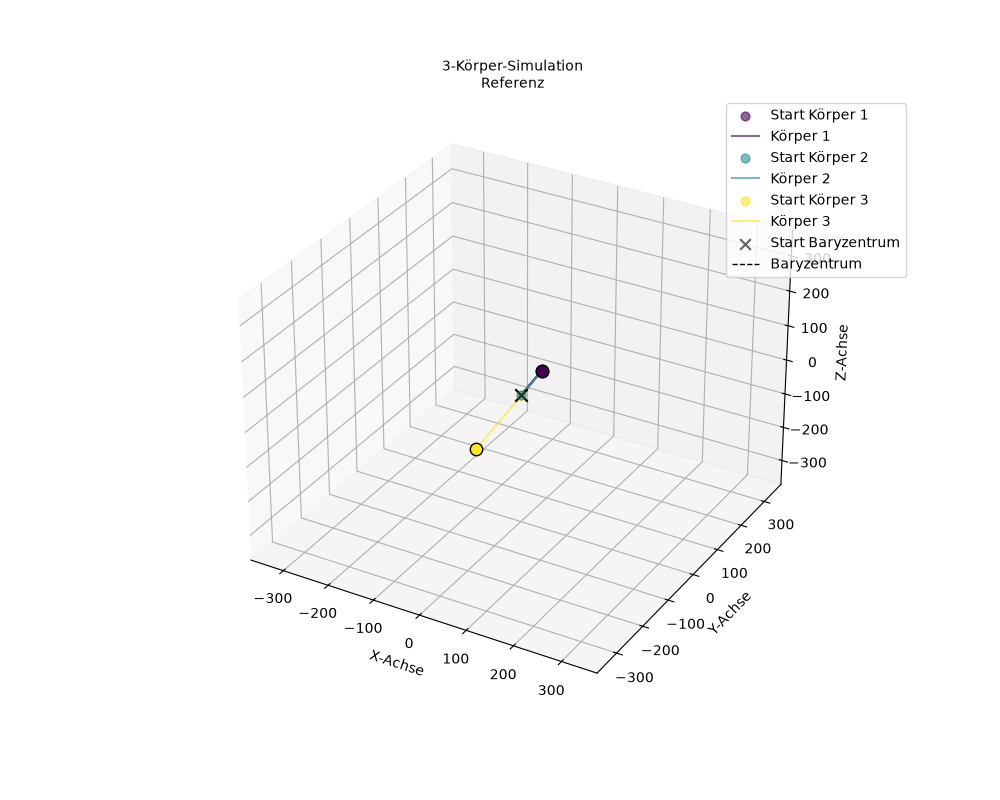

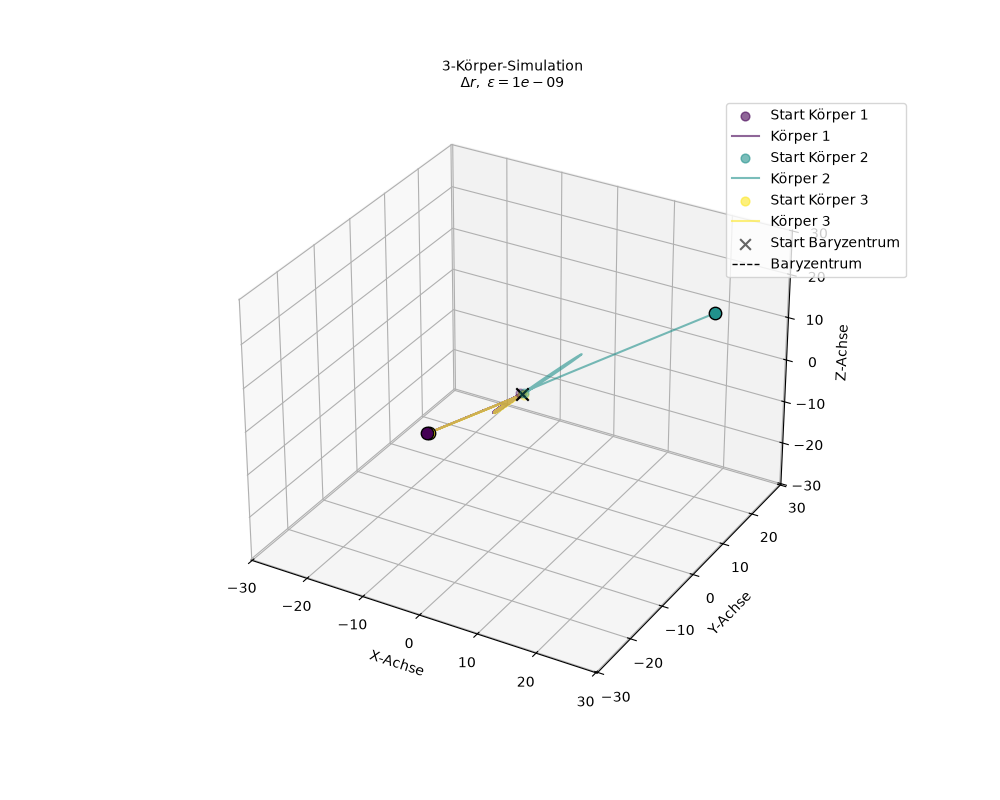

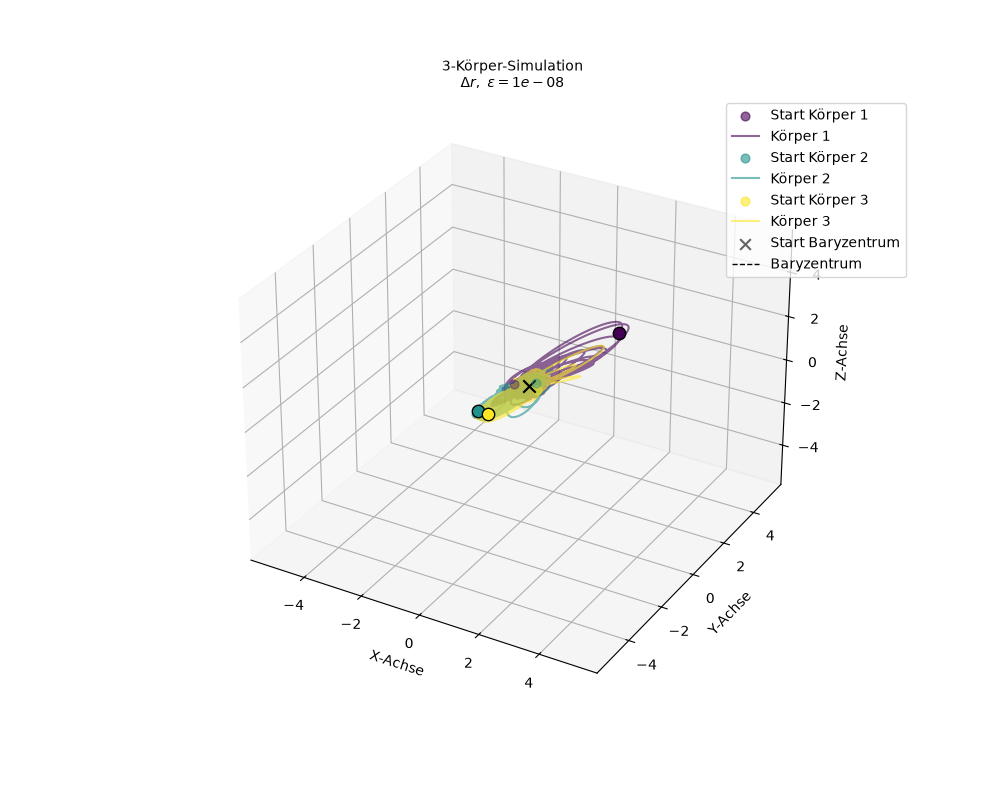

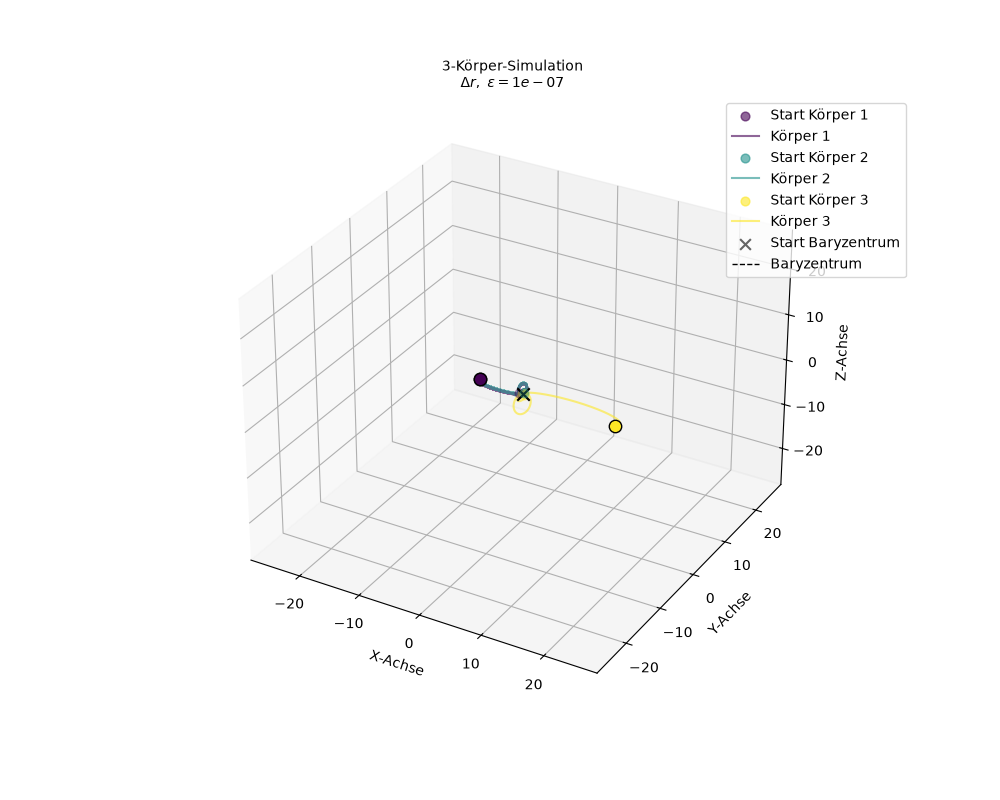

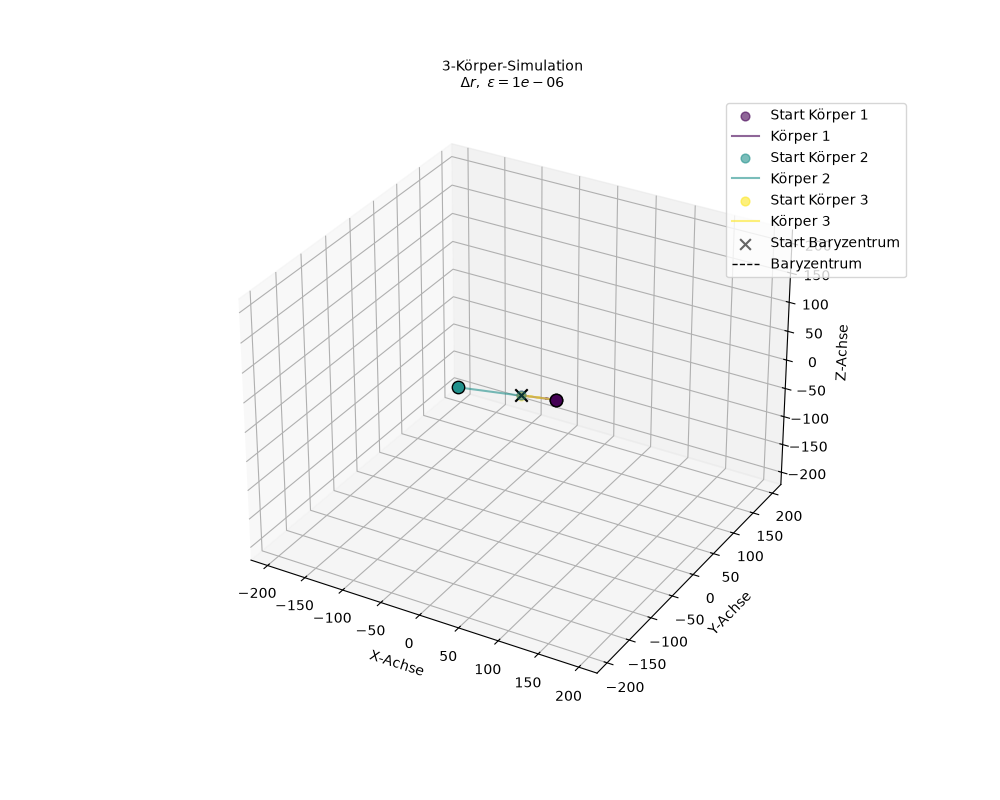

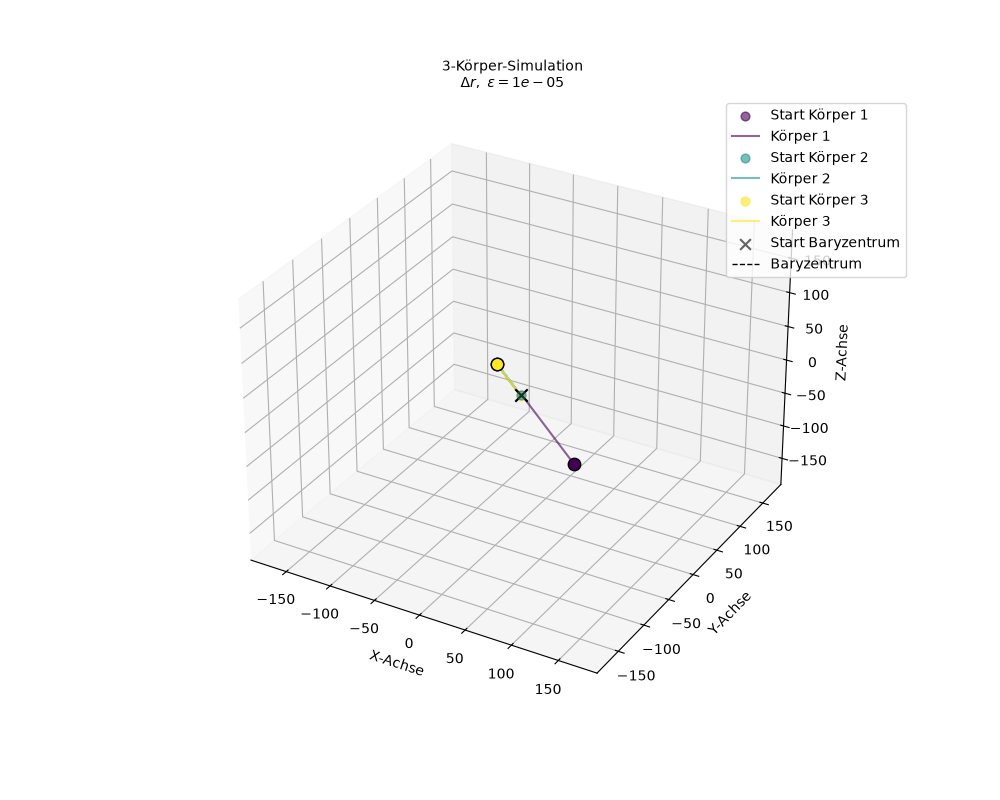

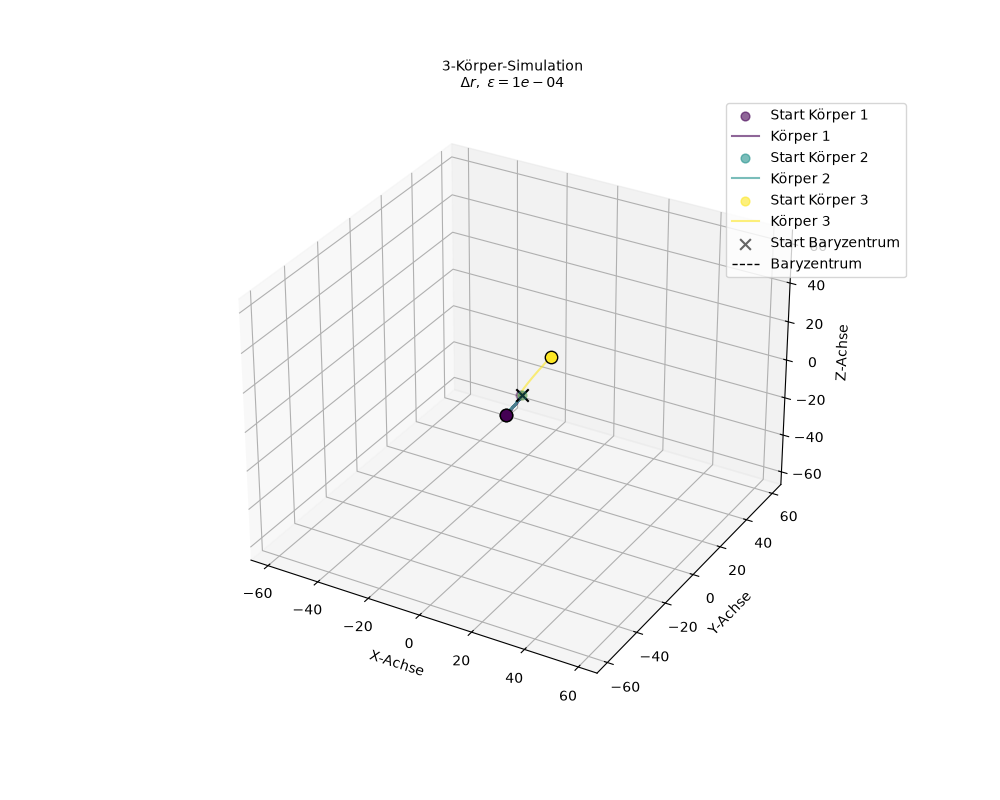

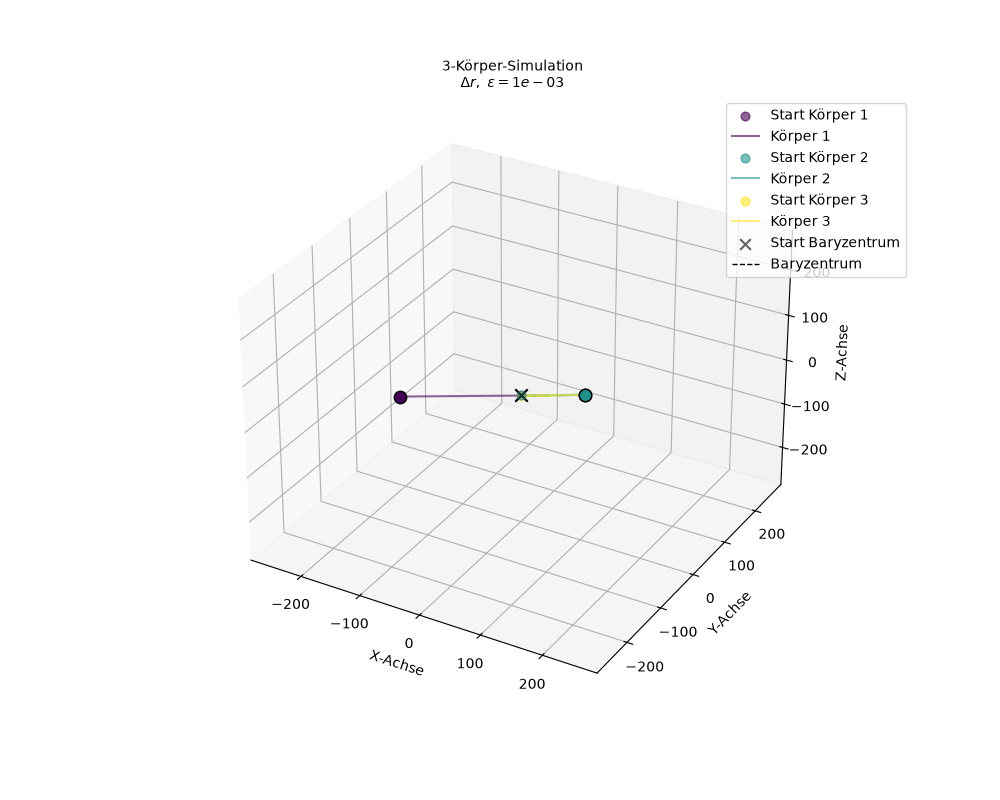

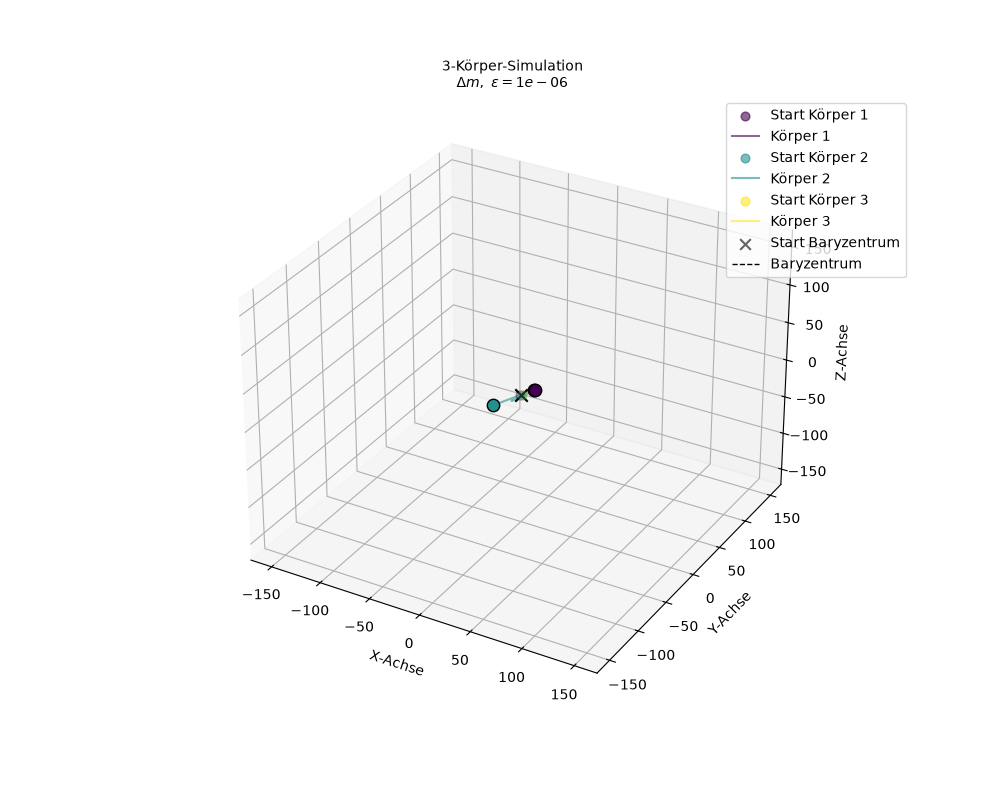

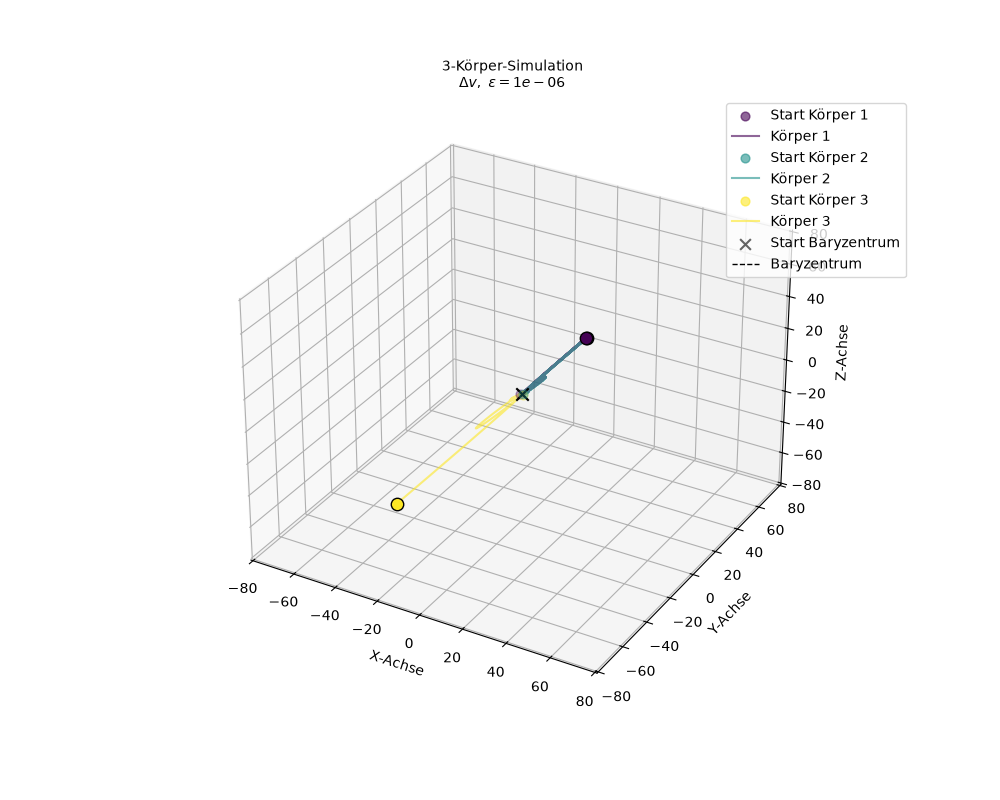

In [9]:
variants_chaos = [("Referenz", sol_ref_chaos.y, m_ref_chaos)] # Benennung der jeweiligen Plots

for eps in epsilons:  # alle pert mit epsilon auf Pos.
    sol_pert_chaos_n, m_pert_chaos = sols_chaos_r[eps]
    variants_chaos.append((f"$\\Delta r,\\ \\varepsilon={eps:.0e}$", sol_pert_chaos_n.y, m_pert_chaos)) # Die Titel um die jeweiligen Epsilons ergänzt

variants_chaos.append((f"$\\Delta m,\\ \\varepsilon={eps_fixed:.0e}$", sol_chaos_m.y, m_chaos_m)) # Pert auf m (eps_fixed:.0e macht wissenschaftliche Schreibweise)
variants_chaos.append((f"$\\Delta v,\\ \\varepsilon={eps_fixed:.0e}$", sol_chaos_v.y, m_chaos_v)) # Pert auf v

figs_chaos = {}  # Hier im Wörterbuch alle Fig. gespeichert
for label, y, m in variants_chaos:
    fig = an.create_plot(y, m)
    fig.axes[0].set_title(f"{fig.axes[0].get_title()}\n{label}", fontsize=10)
    figs_chaos[label] = fig

Visualisierung des Abstandes zwischen den Zuständen auf einer natürlichen Logarithmus-Skala

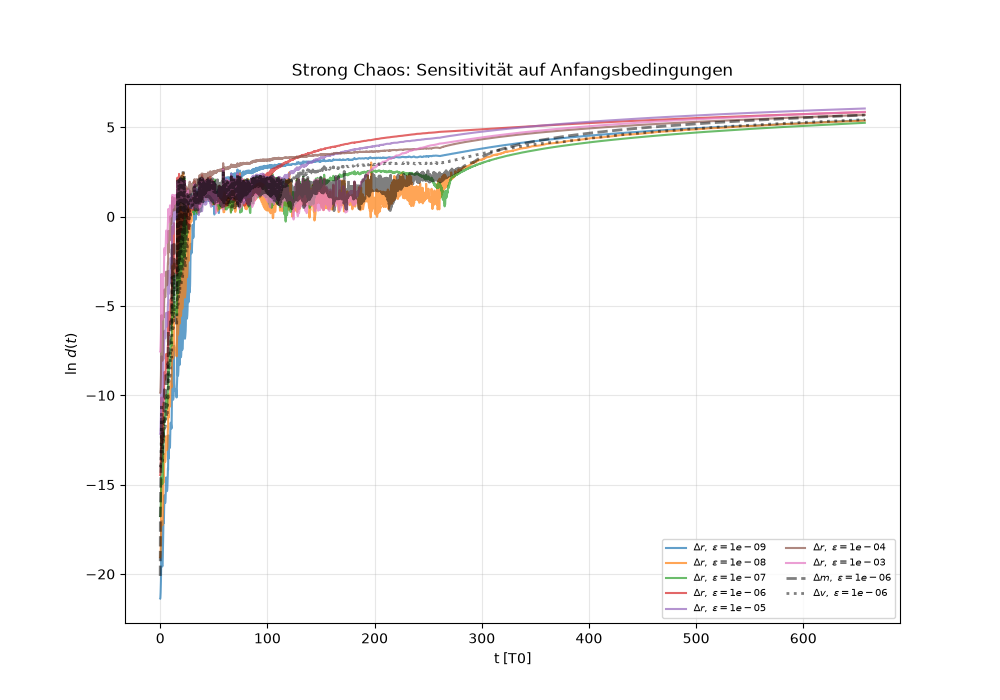

In [5]:
fig, ax = plt.subplots(figsize=(10,7))

for eps in epsilons:
    t_chaos, d_chaos = results_chaos_r[eps]
    ax.plot(t_chaos, np.log(d_chaos), label=f"$\\Delta r,\\ \\varepsilon={eps:.0e}$", alpha=0.7)

ax.plot(t_chaos_m[1:], np.log(d_chaos_m[1:]), "k--", lw=2, label=f"$\\Delta m,\\ \\varepsilon={eps_fixed:.0e}$", alpha=0.5) # Bei t=1 anstelle von t=0 starten, da sonst d(0)=log(0) bei der Masse vorhanden ist --> unsauber
ax.plot(t_chaos_v, np.log(d_chaos_v), "k:",  lw=2, label=f"$\\Delta v,\\ \\varepsilon={eps_fixed:.0e}$", alpha=0.5)

ax.set_xlabel("t [T0]")
ax.set_ylabel(r"$\ln\,d(t)$")
ax.set_title("Strong Chaos: Sensitivität auf Anfangsbedingungen")
ax.legend(fontsize=7, ncol=2)
ax.grid(True, alpha=0.3)

**Sensitivität Euler-Lösung**

Berechnungen durchführen

In [6]:
# Referenz
y0_ref_euler, m_ref_euler, G, r_ref_euler, v_ref_euler = ab.initial_conditions_euler()
units_euler = an.compute_nbody_units(m_ref_euler, r_ref_euler, G)

# Periode berechnen, t_eval an Perioden koppeln (statt fixer t_end wie bei Chaos)
T_euler = an.period_euler(m_ref=1.0, a=1.0, G=G)
n_orbits = 100
t_start = 0
t_end = n_orbits * T_euler
frames = 200 * n_orbits

# sol für Referenz berechnen
sol_ref_euler = int.run_n_body_simulation(y0_ref_euler, m_ref_euler, G, t_start=t_start, t_end=t_end, frames=frames)
sol_ref_euler_n = an.normalize_trajectory(sol_ref_euler, units_euler, N=3, m=m_ref_euler)

# Voller epsilon-Scan auf Position
results_euler_r = {} # Wörterbuch für Resultate erstellen. Resultate = Störung anhand von epsilon auf Position (r), nur t, d
sols_euler_r = {} # Wörterbuch für vollständige Lösung erstellen

for eps in epsilons:
    y0_pert_euler, m_pert_euler, G, r_pert_euler, v_pert_euler = ab.initial_conditions_euler(delta_r={0: np.array([eps, 0.0, 0.0])}) # Störung des Epsilons auf x1 angewandt
    sol_pert_euler = int.run_n_body_simulation(y0_pert_euler, m_pert_euler, G, t_start=t_start, t_end=t_end, frames=frames)
    sol_pert_euler_n = an.normalize_trajectory(sol_pert_euler, units_euler, N=3, m=m_pert_euler)
    t_euler, d_euler = an.separation(sol_ref_euler_n, sol_pert_euler_n)
    results_euler_r[eps] = (t_euler, d_euler) # Resultat ins Wörterbuch results_euler_r
    sols_euler_r[eps] = (sol_pert_euler_n, m_pert_euler) # Resultate ins Wörterbuch sols_euler_r


# Einzelne Vorgänge für Masse und Geschwindigkeit
# eps_fixed bereits definiert (1e-6), bei Strong_Chaos

# Störung auf Masse
y0_euler_m, m_euler_m, G, r_euler_m, v_euler_m = ab.initial_conditions_euler(delta_m=(eps_fixed, 0.0, 0.0)) # _m für gestörte Masse
sol_euler_m = int.run_n_body_simulation(y0_euler_m, m_euler_m, G, t_start=t_start, t_end=t_end, frames=frames)
sol_euler_m_n = an.normalize_trajectory(sol_euler_m, units_euler, N=3, m=m_euler_m)
t_euler_m, d_euler_m = an.separation(sol_ref_euler_n, sol_euler_m_n)

# Störung auf Geschwindigkeit
y0_euler_v, m_euler_v, G, r_euler_v, v_euler_v = ab.initial_conditions_euler(delta_v={0: np.array([eps_fixed, 0.0, 0.0])}) # _v für gestörte Geschwindigkeit
sol_euler_v = int.run_n_body_simulation(y0_euler_v, m_euler_v, G, t_start=t_start, t_end=t_end, frames=frames)
sol_euler_v_n = an.normalize_trajectory(sol_euler_v, units_euler, N=3, m=m_euler_v)
t_euler_v, d_euler_v = an.separation(sol_ref_euler_n, sol_euler_v_n)

Visualisierung

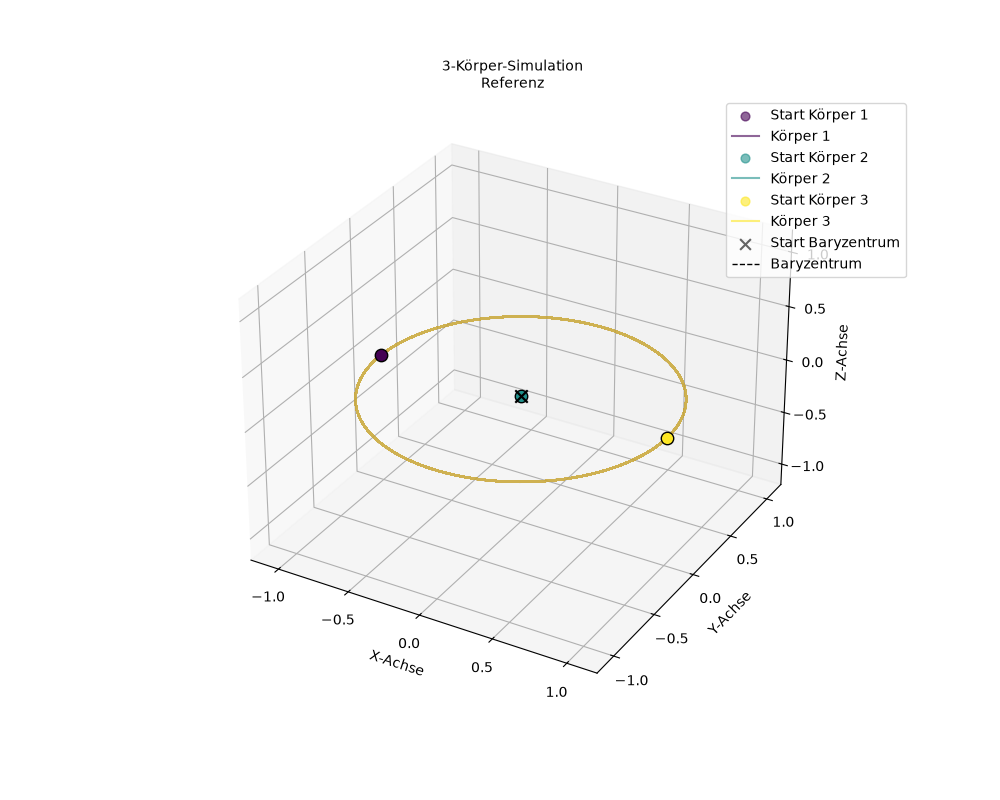

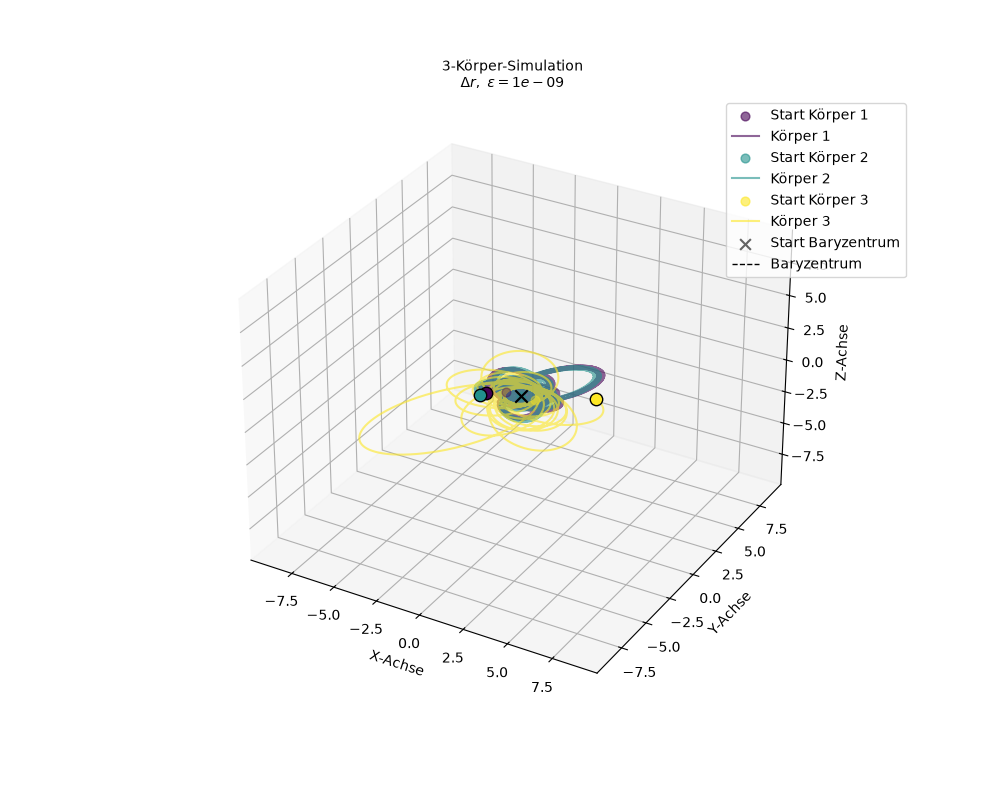

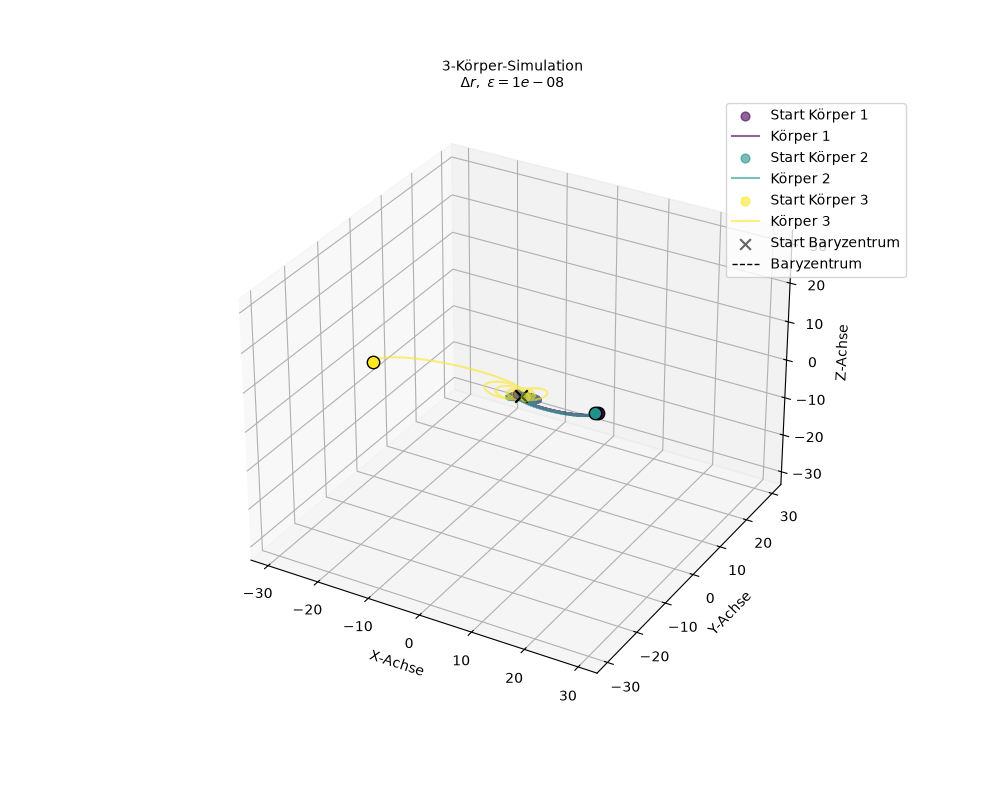

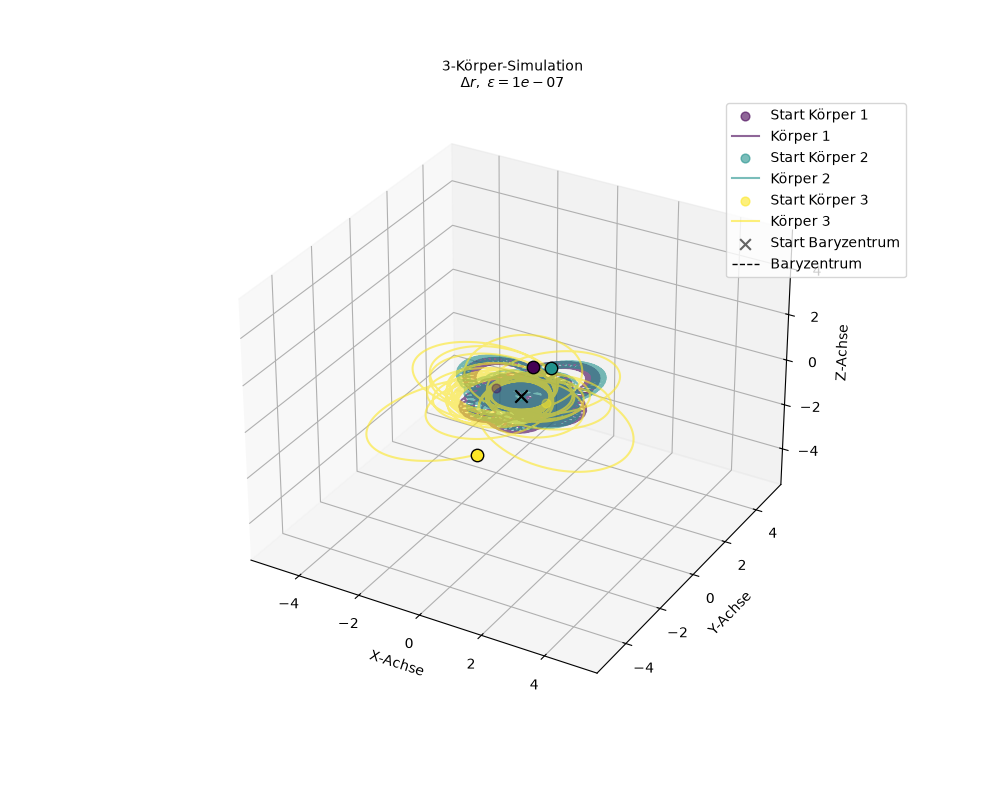

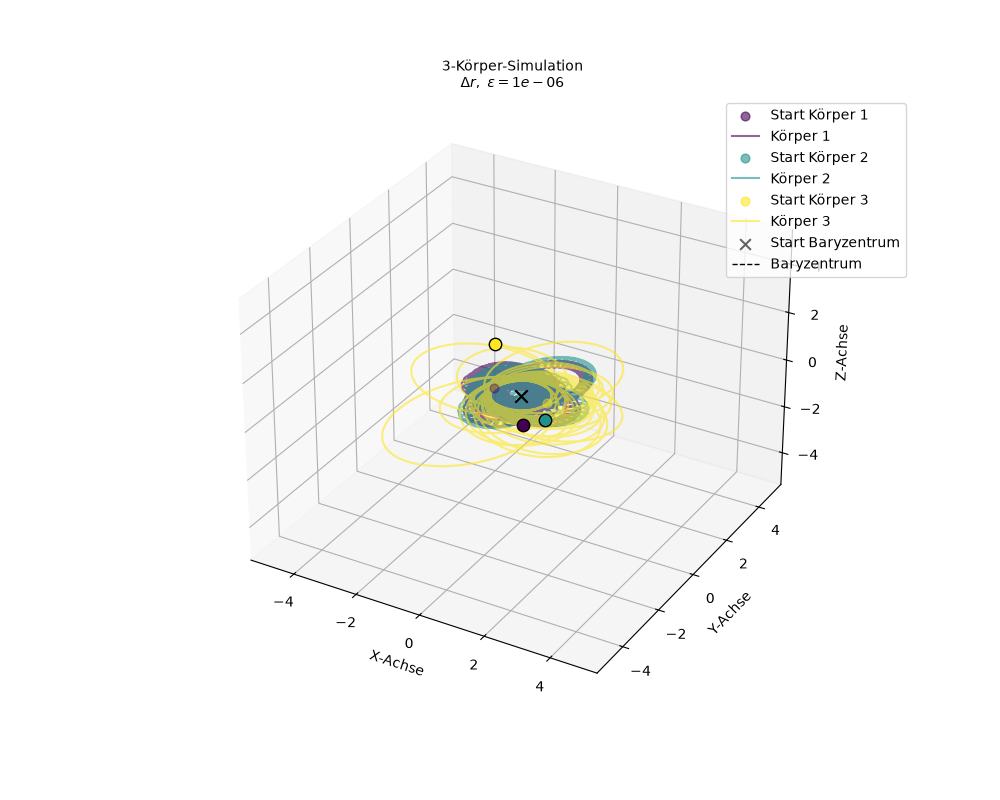

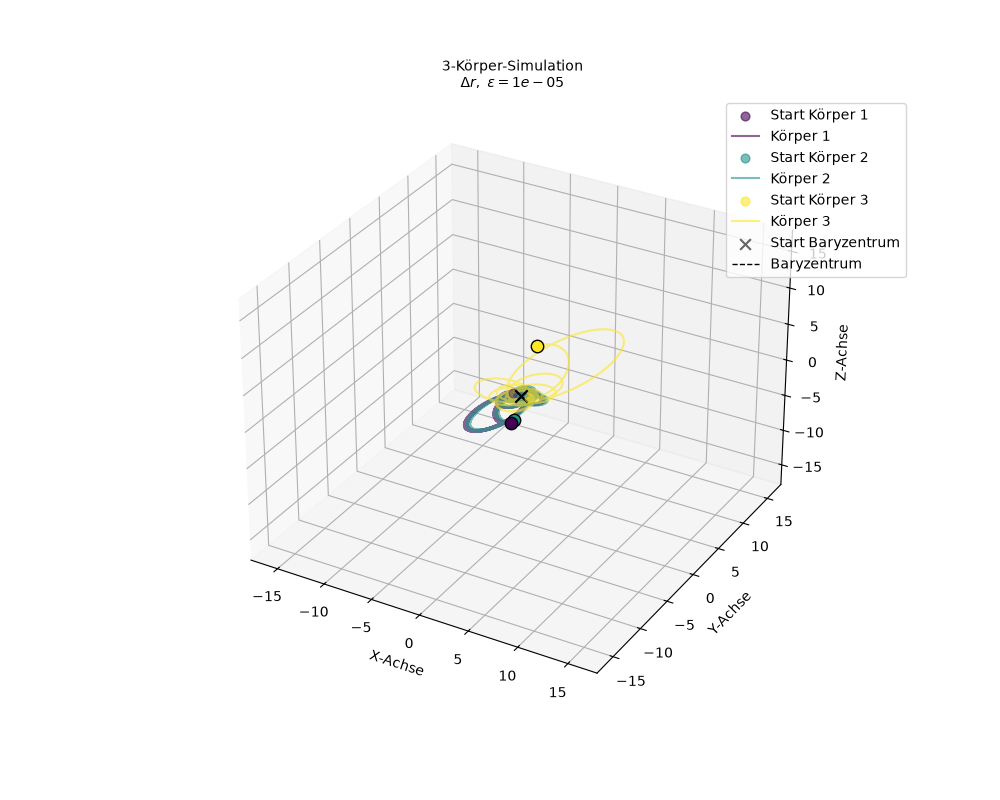

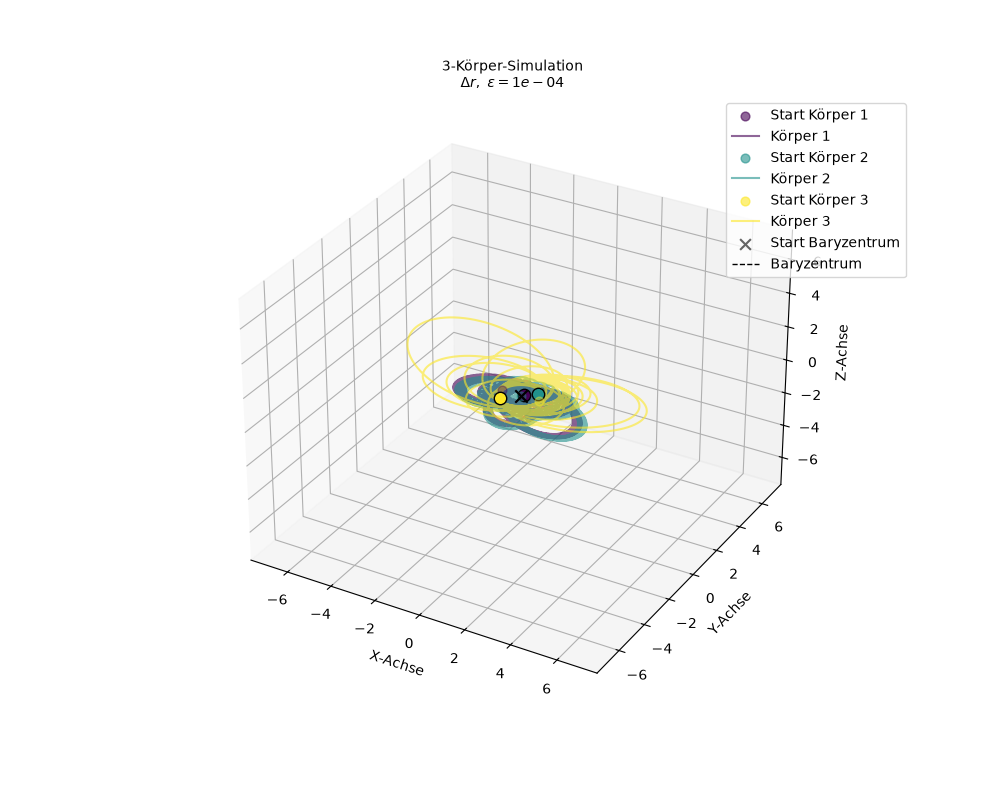

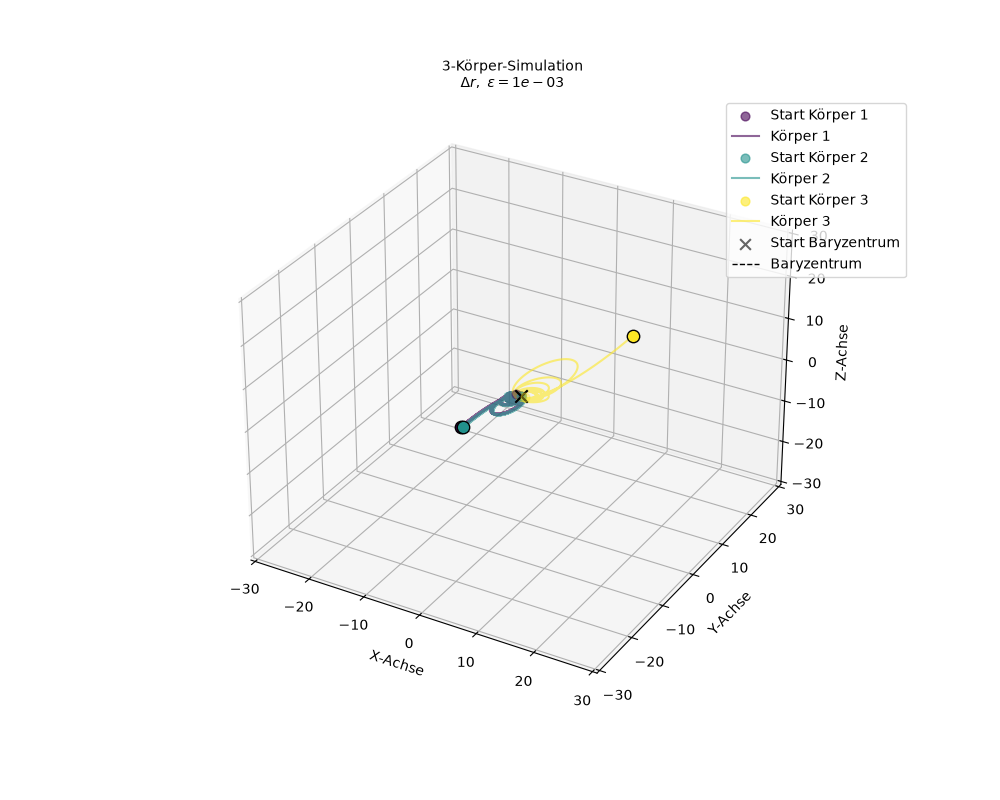

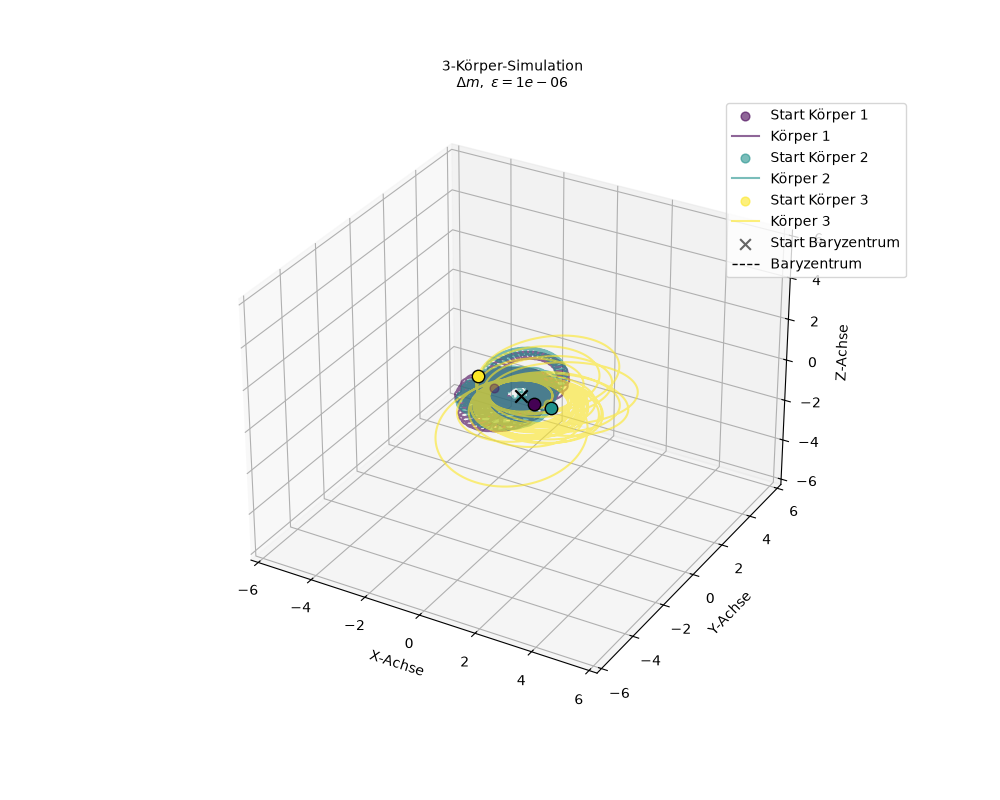

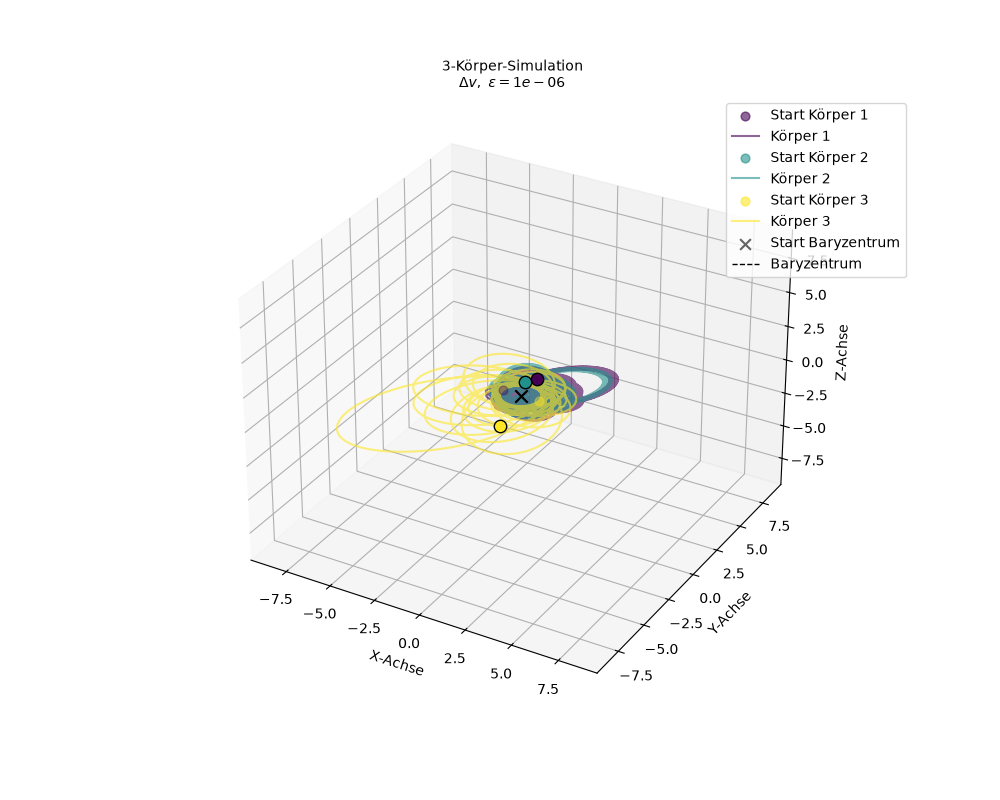

In [8]:
variants_euler = [("Referenz", sol_ref_euler.y, m_ref_euler)] # Benennung der jeweiligen Plots

for eps in epsilons:  # alle pert mit epsilon auf Pos.
    sol_pert_euler_n, m_pert_euler = sols_euler_r[eps]
    variants_euler.append((f"$\\Delta r,\\ \\varepsilon={eps:.0e}$", sol_pert_euler_n.y, m_pert_euler)) # Die Titel um die jeweiligen Epsilons ergänzt

variants_euler.append((f"$\\Delta m,\\ \\varepsilon={eps_fixed:.0e}$", sol_euler_m.y, m_euler_m)) # Pert auf m
variants_euler.append((f"$\\Delta v,\\ \\varepsilon={eps_fixed:.0e}$", sol_euler_v.y, m_euler_v)) # Pert auf v

figs_euler = {} # Hier im Wörterbuch alle Fig. gespeichert
for label, y, m in variants_euler:
    fig = an.create_plot(y, m)
    fig.axes[0].set_title(f"{fig.axes[0].get_title()}\n{label}", fontsize=10)
    figs_euler[label] = fig

Visualisierung des Abstandes zwischen den Zuständen auf einer natürlichen Logarithmus-Skala

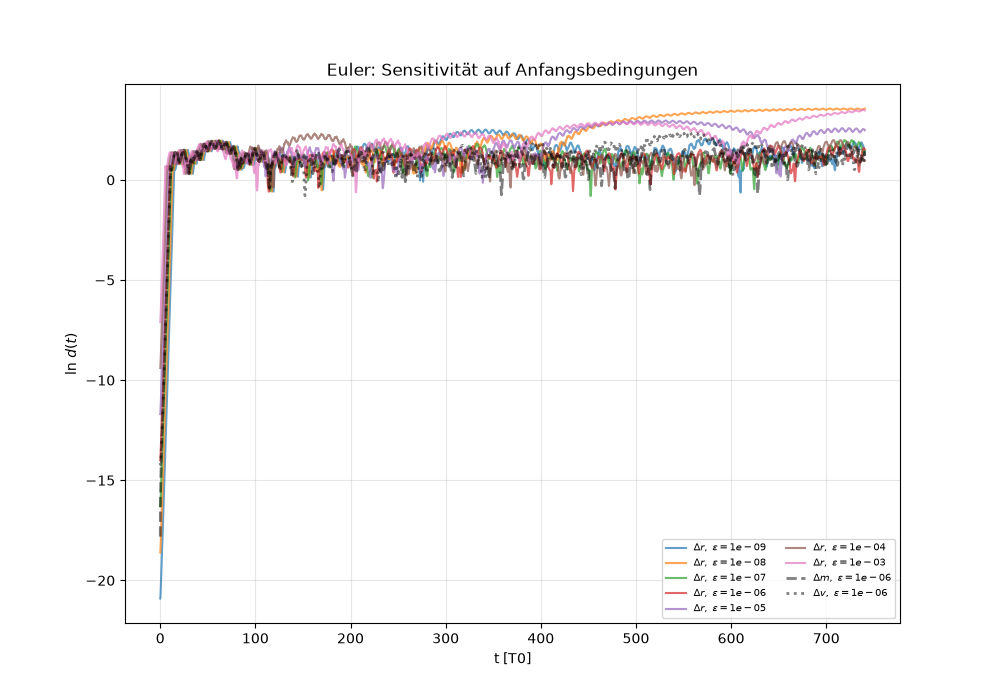

In [7]:
fig, ax = plt.subplots(figsize=(10,7))

for eps in epsilons:
    t_euler, d_euler = results_euler_r[eps]
    ax.plot(t_euler, np.log(d_euler), label=f"$\\Delta r,\\ \\varepsilon={eps:.0e}$", alpha=0.7)

ax.plot(t_euler_m[1:], np.log(d_euler_m[1:]), "k--", lw=2, label=f"$\\Delta m,\\ \\varepsilon={eps_fixed:.0e}$", alpha=0.5) # Bei t=1 anstelle von t=0 starten, da sonst d(0)=log(0) bei der Masse vorhanden ist --> unsauber
ax.plot(t_euler_v, np.log(d_euler_v), "k:",  lw=2, label=f"$\\Delta v,\\ \\varepsilon={eps_fixed:.0e}$", alpha=0.5)

ax.set_xlabel("t [T0]")
ax.set_ylabel(r"$\ln\,d(t)$")
ax.set_title("Euler: Sensitivität auf Anfangsbedingungen")
ax.legend(fontsize=7, ncol=2)
ax.grid(True, alpha=0.3)

In [21]:
# plt.close("all")